In [ ]:
# Name: Praveen Kumar Sarkar
# Reg No. GF202455013
# Course: B.Tech AI P6

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

In [11]:
def load_data() -> pd.DataFrame:
    """Loads the California Housing dataset into a Pandas DataFrame."""
    print("Loading California Housing dataset...")
    california = fetch_california_housing()
    df = pd.DataFrame(california.data, columns=california.feature_names)
    # Adding target variable for completeness, though features are the primary focus
    df['MedHouseVal'] = california.target 
    return df

In [12]:
def plot_histograms(df: pd.DataFrame):
    """Generates histograms to analyze the distribution of all numerical features."""
    print("Generating histograms...")
    df.hist(bins=50, figsize=(16, 12), color='steelblue', edgecolor='black')
    plt.suptitle('Distribution of Numerical Features (Histograms)', fontsize=18, y=1.02)
    plt.tight_layout()
    plt.show()

In [13]:
def plot_boxplots(df: pd.DataFrame):
    """Generates box plots for all numerical features to visualize outliers."""
    print("Generating box plots...")
    num_cols = len(df.columns)
    # Calculate grid size
    rows = int(np.ceil(num_cols / 3))
    
    plt.figure(figsize=(16, rows * 4))
    for i, col in enumerate(df.columns, 1):
        plt.subplot(rows, 3, i)
        sns.boxplot(y=df[col], color='lightgreen')
        plt.title(f'Box plot of {col}')
        plt.ylabel('')
        
    plt.suptitle('Outlier Visualization via Box Plots', fontsize=18, y=1.02)
    plt.tight_layout()
    plt.show()

In [14]:
def identify_outliers_iqr(df: pd.DataFrame):
    """Identifies and counts outliers for each feature using the Interquartile Range (IQR) method."""
    print("\n--- Outlier Analysis (IQR Method) ---")
    outlier_summary = []
    
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
        outliers_count = outliers_mask.sum()
        percentage = (outliers_count / len(df)) * 100
        
        outlier_summary.append({
            'Feature': col,
            'Outlier Count': outliers_count,
            'Percentage (%)': round(percentage, 2)
        })
        
    summary_df = pd.DataFrame(outlier_summary).sort_values(by='Outlier Count', ascending=False)
    print(summary_df.to_string(index=False))
    return summary_df

Loading California Housing dataset...
Generating histograms...


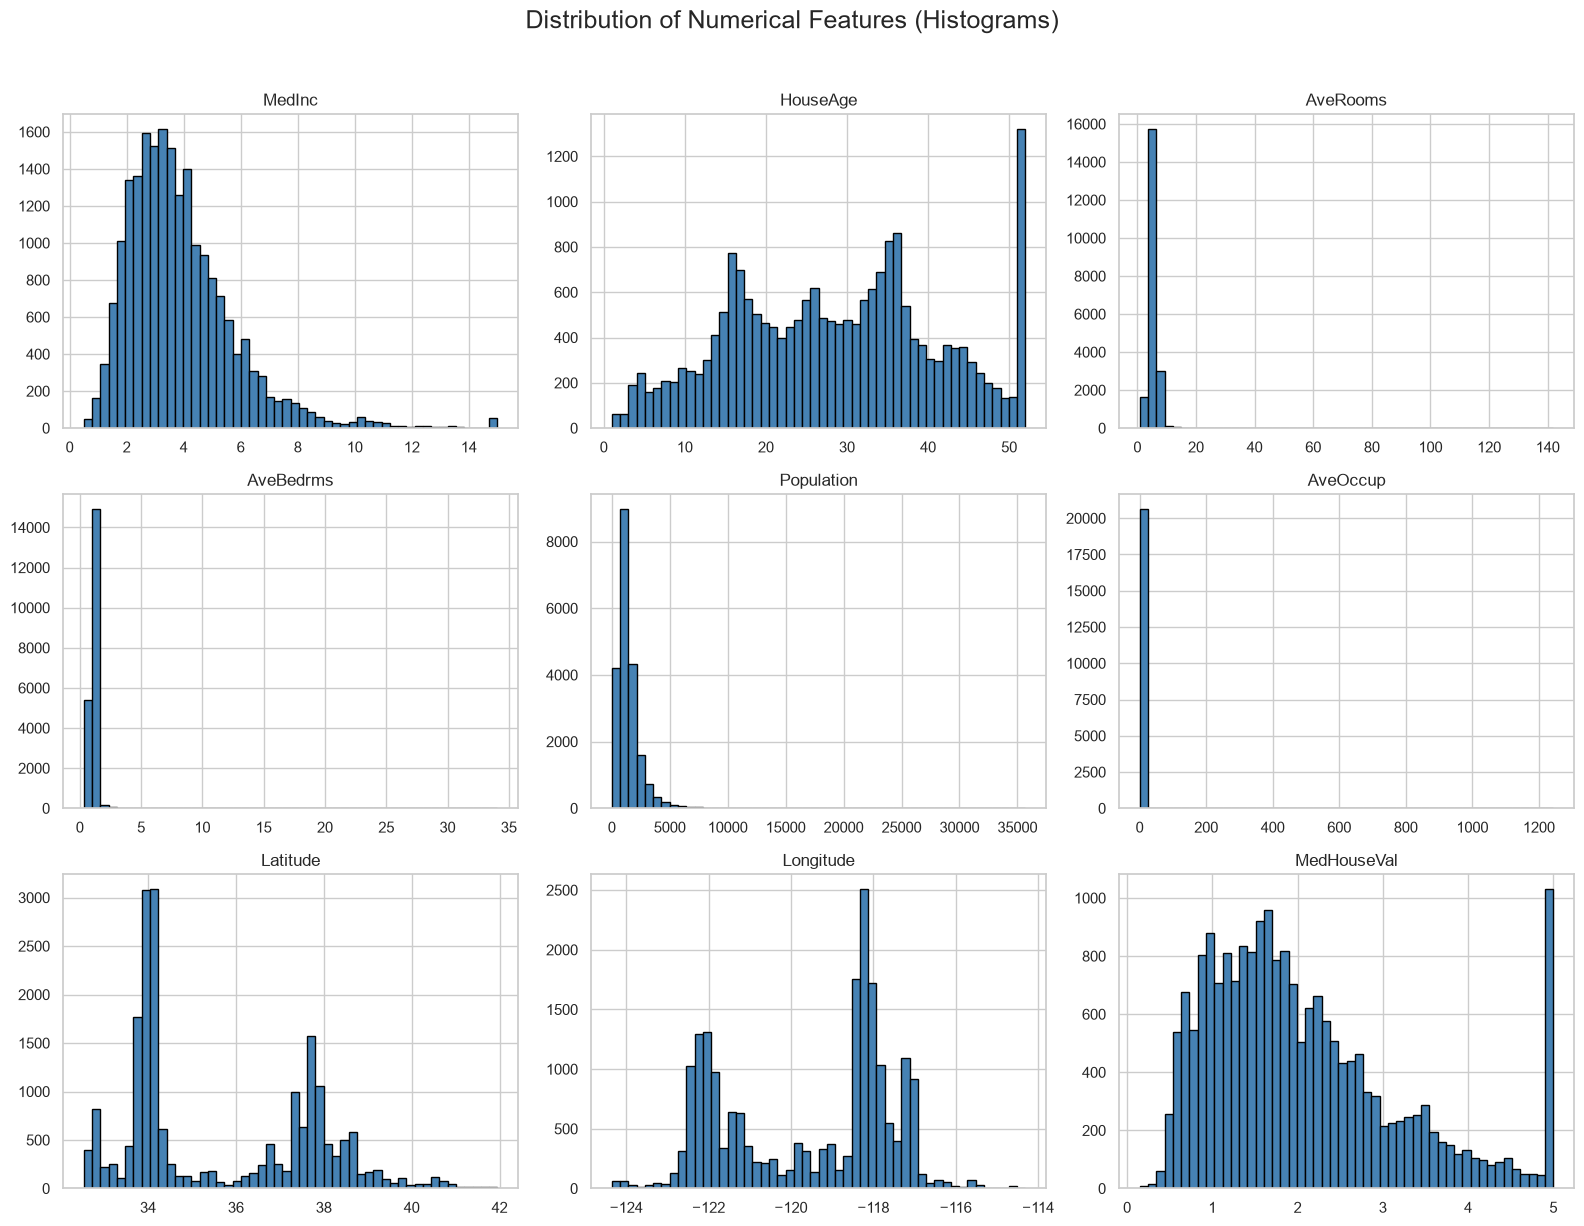

Generating box plots...


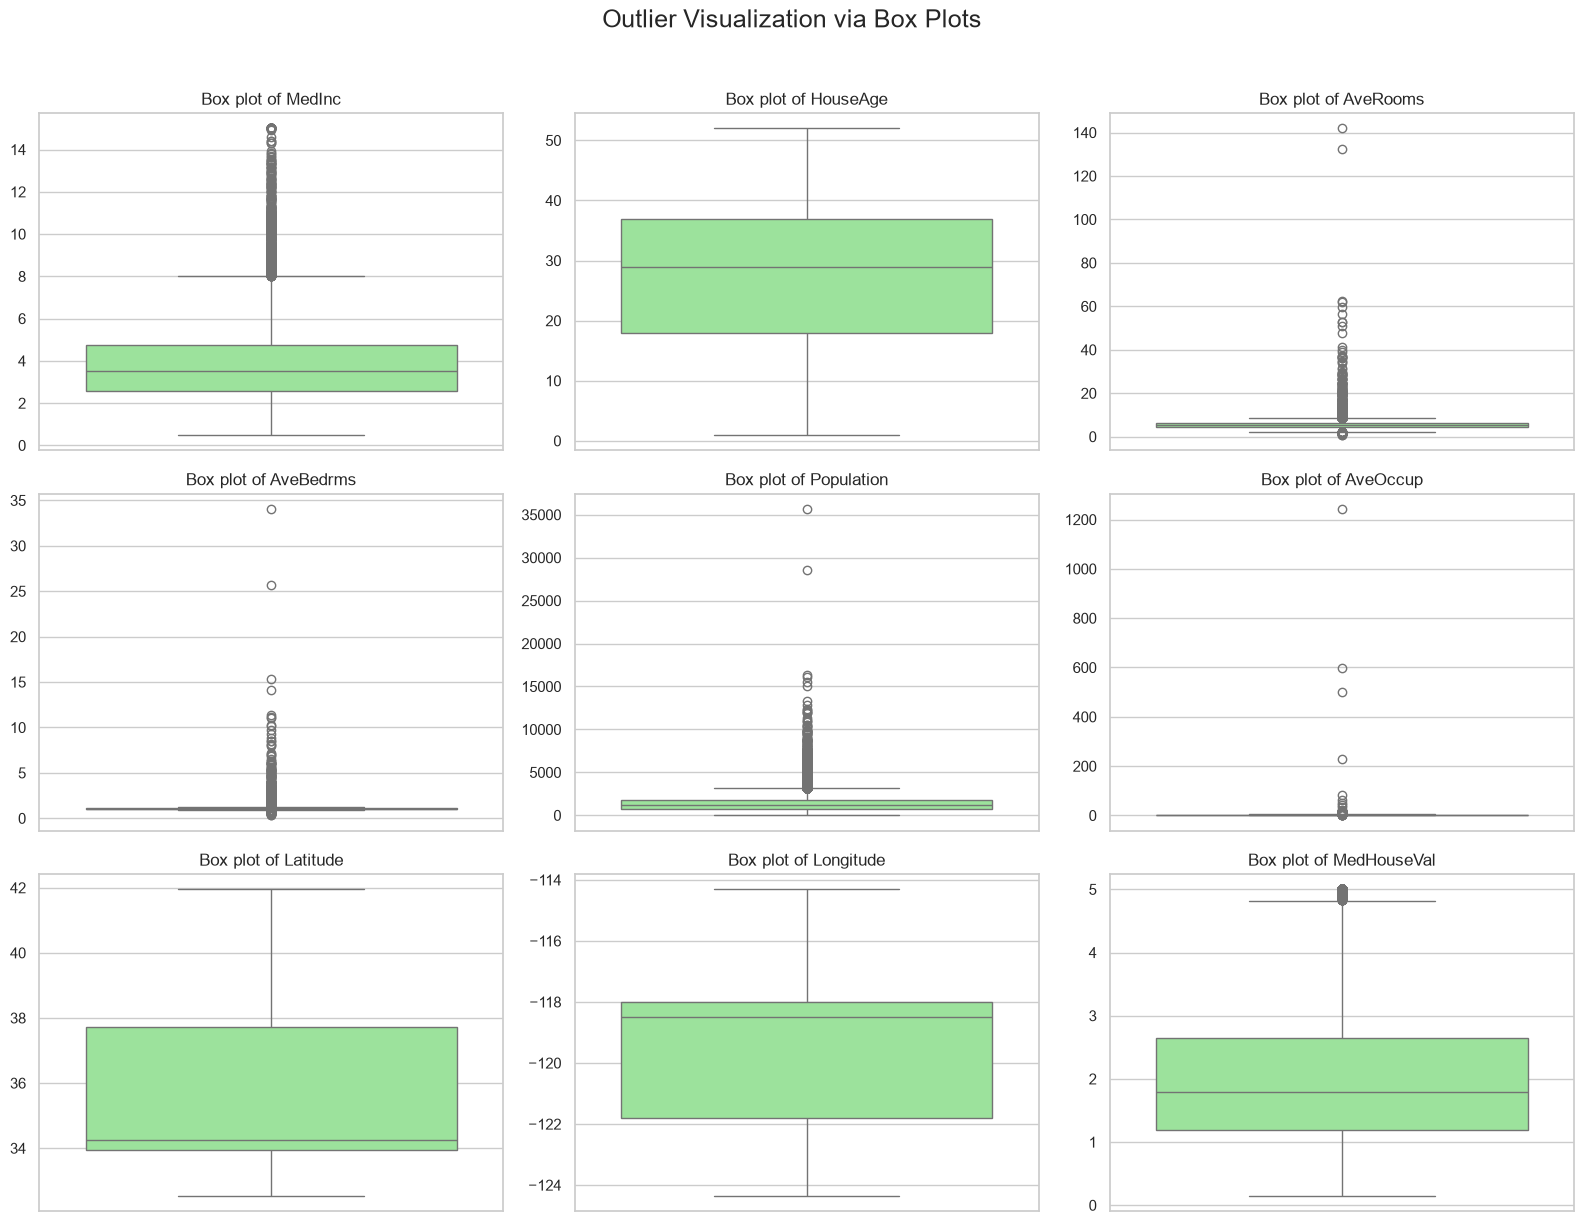


--- Outlier Analysis (IQR Method) ---
    Feature  Outlier Count  Percentage (%)
  AveBedrms           1424            6.90
 Population           1196            5.79
MedHouseVal           1071            5.19
   AveOccup            711            3.44
     MedInc            681            3.30
   AveRooms            511            2.48
   HouseAge              0            0.00
   Latitude              0            0.00
  Longitude              0            0.00


In [15]:
def main():
    # Set plot styling for professional aesthetic
    sns.set_theme(style="whitegrid")
    
    # 1. Load Data
    df = load_data()
    
    # 2. Create Histograms (Distribution Analysis)
    plot_histograms(df)
    
    # 3. Create Box Plots
    plot_boxplots(df)
    
    # 4. Identify Outliers
    identify_outliers_iqr(df)

if __name__ == "__main__":
    main()

Loading California Housing dataset...
Model comparison (lower MAE/RMSE and higher R2 are better):
                      Model    MAE   RMSE     R2
Histogram gradient boosting 0.2989 0.4507 0.8450
                Extra trees 0.3243 0.5005 0.8089
              Random forest 0.3232 0.5005 0.8088
          Linear regression 0.5332 0.7456 0.5758

Best model: Histogram gradient boosting


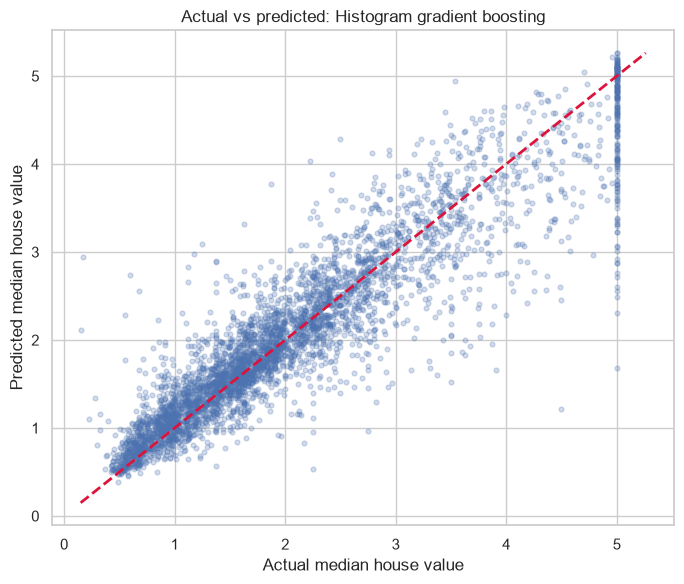

In [ ]:
# 5. Train and evaluate prediction models
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load here because main() keeps its local dataframe private.
df = load_data()
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    'Linear regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'Random forest': RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, max_features=0.8,
        random_state=42, n_jobs=-1
    ),
    'Extra trees': ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=1, max_features=1.0,
        random_state=42, n_jobs=-1
    ),
    'Histogram gradient boosting': HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
        l2_regularization=0.1, random_state=42
    )
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predicted),
        'RMSE': mean_squared_error(y_test, predicted) ** 0.5,
        'R2': r2_score(y_test, predicted)
    })

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
print('Model comparison (lower MAE/RMSE and higher R2 are better):')
print(results_df.round(4).to_string(index=False))

best_model_name = results_df.loc[0, 'Model']
best_predictions = predictions[best_model_name]
print(f'\nBest model: {best_model_name}')

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.25, s=12)
limits = [min(y_test.min(), best_predictions.min()), max(y_test.max(), best_predictions.max())]
plt.plot(limits, limits, '--', color='crimson', linewidth=2)
plt.xlabel('Actual median house value')
plt.ylabel('Predicted median house value')
plt.title(f'Actual vs predicted: {best_model_name}')
plt.tight_layout()
plt.show()
